### Strathmore Institute of Mathematical Sciences | Master of Science in Data Science and Analytics
### DSA 8401 Applied Machine Learning | Capstone
#### 084045


#### Capstone Project: An End-to-End Behavioural Early-Warning Engine for Bank Account Dormancy and Disengagement Risk

**Dataset:** ai-lab/MBD-mini  
**Source:** Hugging Face 

### Imports

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose  import ColumnTransformer

from sklearn.preprocessing import (RobustScaler, OneHotEncoder)

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print(f'Imports completed')

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Imports completed


In [3]:
# install hugging face package
%pip install -U datasets huggingface_hub pandas

Note: you may need to restart the kernel to use updated packages.


### Data Download

**Source:** [MBD-mini](https://huggingface.co/datasets/ai-lab/MBD-mini) (Sber AI Lab,
licence CC BY 4.0), a 10% client sample of the Multimodal Banking Dataset
([Mollaev et al., 2024](https://arxiv.org/abs/2409.17587)).

The repository holds four archives. Download detail, client_split, targets and ptls files:

| Archive | Contents|
|---|---|
| `detail.tar.gz` | Raw event tables: transactions, geo-activity, support dialogues|
| `client_split.tar.gz` | Client-to-fold assignment|
| `targets.tar.gz` | The authors' monthly product-purchase targets|
| `ptls.tar.gz` | Pre-aggregated sequences for one specific library|

In [4]:
# download MBD-mini file; target.tar.gz 
from huggingface_hub import hf_hub_download

targets_path = hf_hub_download(
    repo_id="ai-lab/MBD-mini",
    filename="targets.tar.gz",
    repo_type="dataset"
)

print(targets_path)

/Users/tintin/.cache/huggingface/hub/datasets--ai-lab--MBD-mini/snapshots/4b0d5b4c0b014e02af6c2e6b7b27851e6fb0d5c3/targets.tar.gz


In [5]:
# download  detail.tar.gz file
from huggingface_hub import hf_hub_download

detail_path = hf_hub_download(
    repo_id="ai-lab/MBD-mini",
    filename="detail.tar.gz",
    repo_type="dataset"
)

print(detail_path)

/Users/tintin/.cache/huggingface/hub/datasets--ai-lab--MBD-mini/snapshots/4b0d5b4c0b014e02af6c2e6b7b27851e6fb0d5c3/detail.tar.gz


In [6]:
# download  client_split.tar.gz file
from huggingface_hub import hf_hub_download

client_split_path = hf_hub_download(
    repo_id="ai-lab/MBD-mini",
    filename="client_split.tar.gz",
    repo_type="dataset"
)

print(client_split_path)

/Users/tintin/.cache/huggingface/hub/datasets--ai-lab--MBD-mini/snapshots/4b0d5b4c0b014e02af6c2e6b7b27851e6fb0d5c3/client_split.tar.gz


In [7]:
# download  ptls.tar.gz file
from huggingface_hub import hf_hub_download

ptls_path = hf_hub_download(
    repo_id="ai-lab/MBD-mini",
    filename="ptls.tar.gz",
    repo_type="dataset"
)

print(ptls_path)

/Users/tintin/.cache/huggingface/hub/datasets--ai-lab--MBD-mini/snapshots/4b0d5b4c0b014e02af6c2e6b7b27851e6fb0d5c3/ptls.tar.gz


In [8]:
import os

dataset_path = os.path.expanduser("~/Documents/School//School/MSc. DSA 4/DSA 8401 Applied Machine Learning/Capstone Project")

os.makedirs(dataset_path, exist_ok=True)

print(dataset_path)

/Users/tintin/Documents/School//School/MSc. DSA 4/DSA 8401 Applied Machine Learning/Capstone Project


In [9]:
dataset_path = (
    "/Users/tintin/.cache/huggingface/hub/"
    "datasets--ai-lab--MBD-mini/snapshots/"
    "4b0d5b4c0b014e02af6c2e6b7b27851e6fb0d5c3"
)

print(os.path.exists(dataset_path))

True


In [10]:
files = os.listdir(dataset_path)

for file in files:
    if file.endswith(".tar.gz"):
        file_path = os.path.join(dataset_path, file)

        size = os.path.getsize(file_path) / (1024**3)

        print(f"{file}: {size:.2f} GB")

targets.tar.gz: 0.01 GB
ptls.tar.gz: 1.30 GB
detail.tar.gz: 1.83 GB
client_split.tar.gz: 0.00 GB


In [11]:
# extracting all four archives
import tarfile

archives = [
    "targets.tar.gz",
    "client_split.tar.gz",
    "detail.tar.gz",
    "ptls.tar.gz"
]

for archive in archives:

    archive_path = os.path.join(dataset_path, archive)

    folder_name = archive.replace(".tar.gz", "")
    extract_path = os.path.join(dataset_path, folder_name)

    os.makedirs(extract_path, exist_ok=True)

    with tarfile.open(archive_path, "r:gz") as tar:
        tar.extractall(path=extract_path, filter="data")

    print(f"Successfully extracted: {archive}")

Successfully extracted: targets.tar.gz
Successfully extracted: client_split.tar.gz
Successfully extracted: detail.tar.gz
Successfully extracted: ptls.tar.gz


In [12]:
# inspection of extracted files
for folder in ["targets", "client_split", "detail", "ptls"]:

    folder_path = os.path.join(dataset_path, folder)

    print(f"\n{'='*50}")
    print(f"FOLDER: {folder}")
    print('='*50)

    for root, dirs, files in os.walk(folder_path):
        for file in files:
            file_path = os.path.join(root, file)

            size = os.path.getsize(file_path) / (1024**2)

            print(f"{file} | {size:.2f} MB")


FOLDER: targets
_SUCCESS | 0.00 MB
part-00083-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.04 MB
part-00036-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.03 MB
part-00042-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.02 MB
part-00063-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.03 MB
part-00017-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.03 MB
part-00068-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.02 MB
part-00021-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.03 MB
part-00055-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.02 MB
part-00074-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.02 MB
part-00000-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.02 MB
part-00049-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.03 MB
part-00045-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.02 MB
part-00031-44ca8b70-9d42-48f

In [14]:
# locate parquet files
from pathlib import Path

targets_dir = Path(dataset_path) / "targets"

parquet_files = list(targets_dir.rglob("*.parquet"))

print("Number of Parquet files:", len(parquet_files))

# Display the first 5 file paths
for file in parquet_files[:5]:
    print(file.relative_to(targets_dir))

Number of Parquet files: 435
targets/fold=0/part-00083-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet
targets/fold=0/part-00036-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet
targets/fold=0/part-00042-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet
targets/fold=0/part-00063-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet
targets/fold=0/part-00017-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet


In [13]:
%pip install pyarrow

Note: you may need to restart the kernel to use updated packages.


In [15]:
import pyarrow.dataset as ds

In [ ]:
EXTRACTED = Path(dataset_path)

TABLES = {
    "client_split": EXTRACTED / "client_split" / "client_split",
    "trx": EXTRACTED / "detail" / "detail" / "trx",
    "geo": EXTRACTED / "detail" / "detail" / "geo",
    "dialog": EXTRACTED / "detail" / "detail" / "dialog",
    "targets": EXTRACTED / "targets" / "targets",
}

In [17]:
for name, path in TABLES.items():
    print(f"{name}: {'Found' if path.exists() else 'NOT FOUND'}")

client_split: Found
trx: Found
geo: Found
dialog: Found
targets: Found


In [18]:
datasets = {
    name: ds.dataset(path, format="parquet", partitioning="hive")
    for name, path in TABLES.items()
}

### Inventory: size, rows and columns

In [19]:
inventory = []

for name, dset in datasets.items():
    files = list(TABLES[name].rglob("*.parquet"))

    inventory.append({
        "table": name,
        "files": len(files),
        "size_MB": sum(f.stat().st_size for f in files) / 1e6,
        "rows": dset.count_rows(),
        "columns": len(dset.schema),
    })

inventory = pd.DataFrame(inventory).set_index("table")

inventory.style.format({
    "size_MB": "{:,.1f}",
    "rows": "{:,}",
})

,files,size_MB,rows,columns
table,,,,
client_split,1000,7.5,"100,224",2
trx,400,677.3,"38,764,930",15
geo,460,832.5,"66,295,724",6
dialog,415,673.9,"217,205",4
targets,435,11.5,"1,202,688",9


In [ ]:
# inspect tables schema; data types
for name, dset in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"TABLE: {name}")
    print(f"{'=' * 60}")
    print(dset.schema)


TABLE: client_split
client_id: string
fold: int32
-- schema metadata --
org.apache.spark.version: '3.2.1'
org.apache.spark.sql.parquet.row.metadata: '{"type":"struct","fields":[{"' + 66

TABLE: trx
client_id: string
event_time: timestamp[ns]
amount: float
event_type: int32
event_subtype: int32
currency: int32
src_type11: int32
src_type12: int32
dst_type11: int32
dst_type12: int32
src_type21: int32
src_type22: int32
src_type31: int32
src_type32: int32
fold: int32
-- schema metadata --
org.apache.spark.version: '3.2.1'
org.apache.spark.sql.parquet.row.metadata: '{"type":"struct","fields":[{"' + 960

TABLE: geo
client_id: string
event_time: timestamp[ns]
geohash_4: int32
geohash_5: int32
geohash_6: int32
fold: int32
-- schema metadata --
org.apache.spark.version: '3.2.1'
org.apache.spark.sql.parquet.row.metadata: '{"type":"struct","fields":[{"' + 341

TABLE: dialog
client_id: string
event_time: timestamp[ns]
embedding: list<element: float>
  child 0, element: float
fold: int32
-- schema 

In [ ]:
# read data
for name, dset in datasets.items():
    print(f"\nTABLE: {name}")
    display(dset.head(5).to_pandas())


TABLE: client_split


,client_id,fold
0,091d957b9e571dc1ddb66017f32202d3a4f48583b6399a...,0
1,1171cec680efbb4fd268a9ade0e94512c7a6f1e08a98a6...,0
2,127042b9a315782dfba125603f5173144f2b1e9b86b0bd...,0
3,14a3fab5925a8c9271ab9e16c25fedb47122095476a741...,0
4,2421da099471e3c4cca875717d19c6853a80930a01fad1...,0



TABLE: trx


,client_id,event_time,amount,event_type,event_subtype,currency,src_type11,src_type12,dst_type11,dst_type12,src_type21,src_type22,src_type31,src_type32,fold
0,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2022-10-26 13:58:59.938408,1.021543e+06,16,18,11,22,47,780,21619,21490,83,364,58,0
1,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2021-02-09 07:43:20.639579,3.007656e+05,1,12,11,4,958,306,26766,21490,83,364,58,0
2,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2022-10-22 09:12:06.614108,6.061549e+05,16,18,11,22,47,780,21619,21490,83,364,58,0
3,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2021-02-12 15:12:20.660481,8.032591e+04,1,12,11,4,958,306,26766,21490,83,364,58,0
4,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2022-10-08 06:52:28.877461,1.222866e+05,16,18,11,22,47,780,21619,21490,83,364,58,0



TABLE: geo


,client_id,event_time,geohash_4,geohash_5,geohash_6,fold
0,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-03-25 13:39:51.569288,41342,406579,1018528,0
1,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-06-11 07:21:32.505485,41342,406579,1018528,0
2,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-08-08 21:25:07.461323,41342,406579,1018528,0
3,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-07-23 11:32:03.433401,41342,406579,1018528,0
4,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-05-28 08:18:19.843885,41342,406579,1018528,0



TABLE: dialog


,client_id,event_time,embedding,fold
0,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2021-06-18 05:49:23.962741,"[0.393141, -0.036111, 0.311134, -0.197847, -0....",0
1,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2022-06-29 07:39:31.618769,"[0.302206, -0.381503, 0.472719, -0.284991, -0....",0
2,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2022-06-24 06:06:59.691367,"[0.570911, -0.395088, 0.546858, -0.413399, -0....",0
3,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2021-05-12 12:34:32.616245,"[0.232727, -0.284487, 0.584149, -0.524622, -0....",0
4,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2021-10-25 05:25:17.810891,"[0.316968, -0.149733, 0.426037, -0.395491, -0....",0



TABLE: targets


,client_id,mon,target_1,target_2,target_3,target_4,trans_count,diff_trans_date,fold
0,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-02-28,0,0,0,0,10,0,0
1,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-03-31,0,0,0,0,29,0,0
2,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-04-30,0,0,0,0,51,0,0
3,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-05-31,0,0,0,0,52,4,0
4,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-06-30,0,0,0,0,52,35,0


In [22]:
def peek(name: str, n: int = 5) -> pd.DataFrame:
    df = datasets[name].head(n).to_pandas()
    if "embedding" in df:  # 768 floats per row; show the length only
        df["embedding"] = df["embedding"].map(lambda v: f"<{len(v)} floats>")
    return df


print(datasets["trx"].schema.remove_metadata())
peek("trx")

client_id: string
event_time: timestamp[ns]
amount: float
event_type: int32
event_subtype: int32
currency: int32
src_type11: int32
src_type12: int32
dst_type11: int32
dst_type12: int32
src_type21: int32
src_type22: int32
src_type31: int32
src_type32: int32
fold: int32


,client_id,event_time,amount,event_type,event_subtype,currency,src_type11,src_type12,dst_type11,dst_type12,src_type21,src_type22,src_type31,src_type32,fold
0,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2022-10-26 13:58:59.938408,1.021543e+06,16,18,11,22,47,780,21619,21490,83,364,58,0
1,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2021-02-09 07:43:20.639579,3.007656e+05,1,12,11,4,958,306,26766,21490,83,364,58,0
2,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2022-10-22 09:12:06.614108,6.061549e+05,16,18,11,22,47,780,21619,21490,83,364,58,0
3,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2021-02-12 15:12:20.660481,8.032591e+04,1,12,11,4,958,306,26766,21490,83,364,58,0
4,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2022-10-08 06:52:28.877461,1.222866e+05,16,18,11,22,47,780,21619,21490,83,364,58,0


In [23]:
print(datasets["geo"].schema.remove_metadata())
peek("geo")

client_id: string
event_time: timestamp[ns]
geohash_4: int32
geohash_5: int32
geohash_6: int32
fold: int32


,client_id,event_time,geohash_4,geohash_5,geohash_6,fold
0,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-03-25 13:39:51.569288,41342,406579,1018528,0
1,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-06-11 07:21:32.505485,41342,406579,1018528,0
2,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-08-08 21:25:07.461323,41342,406579,1018528,0
3,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-07-23 11:32:03.433401,41342,406579,1018528,0
4,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-05-28 08:18:19.843885,41342,406579,1018528,0


In [24]:
print(datasets["dialog"].schema.remove_metadata())
peek("dialog")

client_id: string
event_time: timestamp[ns]
embedding: list<element: float>
  child 0, element: float
fold: int32


,client_id,event_time,embedding,fold
0,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2021-06-18 05:49:23.962741,<768 floats>,0
1,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2022-06-29 07:39:31.618769,<768 floats>,0
2,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2022-06-24 06:06:59.691367,<768 floats>,0
3,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2021-05-12 12:34:32.616245,<768 floats>,0
4,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2021-10-25 05:25:17.810891,<768 floats>,0


In [25]:
print(datasets["targets"].schema.remove_metadata())
peek("targets")

client_id: string
mon: string
target_1: int32
target_2: int32
target_3: int32
target_4: int32
trans_count: int32
diff_trans_date: int32
fold: int32


,client_id,mon,target_1,target_2,target_3,target_4,trans_count,diff_trans_date,fold
0,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-02-28,0,0,0,0,10,0,0
1,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-03-31,0,0,0,0,29,0,0
2,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-04-30,0,0,0,0,51,0,0
3,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-05-31,0,0,0,0,52,4,0
4,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-06-30,0,0,0,0,52,35,0


In [26]:
print(datasets["client_split"].schema.remove_metadata())
peek("client_split")

client_id: string
fold: int32


,client_id,fold
0,091d957b9e571dc1ddb66017f32202d3a4f48583b6399a...,0
1,1171cec680efbb4fd268a9ade0e94512c7a6f1e08a98a6...,0
2,127042b9a315782dfba125603f5173144f2b1e9b86b0bd...,0
3,14a3fab5925a8c9271ab9e16c25fedb47122095476a741...,0
4,2421da099471e3c4cca875717d19c6853a80930a01fad1...,0


### Time span of each table

In [28]:
import pyarrow.compute as pc

spans = []
for name in ["trx", "geo", "dialog"]:
    lo = hi = None
    for batch in datasets[name].to_batches(columns=["event_time"], batch_size=2_000_000):
        mm = pc.min_max(batch.column(0))
        lo = mm["min"].as_py() if lo is None else min(lo, mm["min"].as_py())
        hi = mm["max"].as_py() if hi is None else max(hi, mm["max"].as_py())
    spans.append({"table": name, "first_event": lo, "last_event": hi})

months = datasets["targets"].to_table(columns=["mon"]).column(0)
spans.append({"table": "targets (mon)", "first_event": pc.min(months).as_py(), "last_event": pc.max(months).as_py()})
pd.DataFrame(spans).set_index("table")

,first_event,last_event
table,,
trx,2020-12-31 21:00:02.169545,2022-12-31 20:59:58.460193
geo,2021-12-11 19:27:07.507106,2022-12-31 20:59:58.725788
dialog,2021-02-10 09:36:07.022271,2022-12-31 20:25:11.730797
targets (mon),2022-02-28,2023-01-31


- **Transactions span 24 months** (January 2021 to December 2022). The dataset card
  says 12 months, which describes the `targets` table, not the event tables.
- **Geo data starts only in December 2021**, so geo features can exist only for scoring
  dates in 2022.

### Which clients appear in which table?

In [29]:
def unique_clients(dset) -> set:
    # Batch by batch: geo alone has 66M rows, and loading its client_id column
    # at once needs more memory than a typical laptop has.
    seen = set()
    for batch in dset.to_batches(columns=["client_id"], batch_size=1_000_000):
        seen.update(pc.unique(batch.column(0)).to_pylist())
    return seen


clients = {name: unique_clients(dset) for name, dset in datasets.items()}
all_clients = clients["client_split"]

coverage = pd.DataFrame({
    "clients": {n: len(c) for n, c in clients.items()},
    "share_of_all_clients": {n: len(c & all_clients) / len(all_clients) for n, c in clients.items()},
    "not_in_client_split": {n: len(c - all_clients) for n, c in clients.items()},
})
coverage.style.format({"clients": "{:,}", "share_of_all_clients": "{:.1%}", "not_in_client_split": "{:,}"})

,clients,share_of_all_clients,not_in_client_split
client_split,"100,224",100.0%,0
trx,"98,721",98.5%,0
geo,"72,573",72.4%,0
dialog,"46,320",46.2%,0
targets,"100,224",100.0%,0


In [30]:
no_trx = all_clients - clients["trx"]
print(f"Clients with no transactions at all: {len(no_trx):,}")
print(f"Clients with transactions but no geo: {len(clients['trx'] - clients['geo']):,}")
print(f"Clients with transactions but no dialogue: {len(clients['trx'] - clients['dialog']):,}")

Clients with no transactions at all: 1,503
Clients with transactions but no geo: 27,074
Clients with transactions but no dialogue: 52,715


### Summary

| | |
|---|---|
| Population | 100,224 corporate clients (`client_split`) |
| Core table | `trx`: 38.8M transactions, 24 months |
| Optional sources | `geo` (2022 only, ~73% of clients), `dialog` (~46% of clients) |
| Not used as a label | `targets` (product purchases, a different task) |

- Dormancy is not given; we will **derive it from `trx`** (no transaction for N days).
- Clients with no transactions can never "become" dormant, so they leave the population.
- Missing `geo` or `dialog` for a client is normal (a missing *modality*), not a data error.

### Data preparation and cleaning

The transaction table has 38.8 million rows. Before choosing a tool, estimate what pandas would need by 
loading one million rows and scaling up.

In [33]:
TRX = EXTRACTED / "detail" / "detail" / "trx"
GEO = EXTRACTED / "detail" / "detail" / "geo"
DIALOG = EXTRACTED / "detail" / "detail" / "dialog"
SPLIT = EXTRACTED / "client_split" / "client_split"

In [34]:
sample = ds.dataset(TRX, format="parquet", partitioning="hive").head(1_000_000).to_pandas()
per_million = sample.memory_usage(deep=True).sum() / 1e9
print(f"pandas memory for 1M rows: {per_million:.2f} GB")
print(f"estimated for all 38.8M rows: {per_million * 38.8:.1f} GB")
del sample

pandas memory for 1M rows: 0.17 GB
estimated for all 38.8M rows: 6.5 GB


The notebook will use **Polars lazy queries**: each query is planned first and then run
in streaming batches, so the full table never sits in memory. Small results (counts,
summaries) are converted to pandas for display and plotting. Cleaning also replaces the
string `client_id` with a compact integer `client_key`.

In [35]:
!pip install polars

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 911.5/911.5 kB 5.6 MB/s eta 0:00:00-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 18.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [polars]2m1/2 [polars]


In [36]:
import polars as pl

In [37]:
trx = pl.scan_parquet(TRX / "**" / "*.parquet", hive_partitioning=True)
geo = pl.scan_parquet(GEO / "**" / "*.parquet", hive_partitioning=True)
dialog = pl.scan_parquet(DIALOG / "**" / "*.parquet", hive_partitioning=True)
split = pl.read_parquet(SPLIT / "**" / "*.parquet", hive_partitioning=True)


def run(lf: pl.LazyFrame) -> pl.DataFrame:
    # Execute a lazy query with the streaming engine
    return lf.collect(engine="streaming")


n_rows_raw = run(trx.select(pl.len())).item()
print(f"trx rows: {n_rows_raw:,}")
print(f"clients in client_split: {split.height:,}")

trx rows: 38,764,930
clients in client_split: 100,224


### Value Types

In [38]:
schema = trx.collect_schema()
pd.DataFrame({"dtype": [str(t) for t in schema.values()]}, index=list(schema.keys()))

,dtype
client_id,String
event_time,"Datetime(time_unit='ns', time_zone=None)"
amount,Float32
event_type,Int32
event_subtype,Int32
currency,Int32
src_type11,Int32
src_type12,Int32
dst_type11,Int32
dst_type12,Int32


In [39]:
# Client lookup table: one integer key per client
client_map = (
    split.sort("client_id")
    .with_row_index("client_key")
    .with_columns(pl.col("client_key").cast(pl.Int32))
    .select("client_key", "client_id", "fold")
)
print(f"{client_map.height:,} clients, keys 0 to {client_map['client_key'].max():,}")
print(f"duplicate client_ids in client_split: {split['client_id'].is_duplicated().sum()}")
client_map.head()

100,224 clients, keys 0 to 100,223
duplicate client_ids in client_split: 0


client_key,client_id,fold
i32,str,i64
0,"""000032cc38caee45fe031778bcf6af…",2
1,"""00005e39da5fb5968996cd49130281…",4
2,"""00012766278a7b25ddd3d6de329a44…",3
3,"""0001edbc5ab720f70a615ed9e8429d…",4
4,"""0002ddd816198d32474486d54f4bfe…",4


### Duplicates

In [40]:
n_unique_rows = run(trx.unique().select(pl.len())).item()
print(f"exact duplicate rows: {n_rows_raw - n_unique_rows:,}")

exact duplicate rows: 0


No two rows are identical across all columns. 

### Missing Values

In [41]:
nulls = run(trx.null_count()).to_pandas().T.rename(columns={0: "null_count"})
nulls["null_pct"] = nulls["null_count"] / n_rows_raw * 100
nulls.sort_values("null_count", ascending=False)

,null_count,null_pct
dst_type11,243824,0.628981
dst_type12,243824,0.628981
src_type11,217361,0.560716
src_type12,217361,0.560716
src_type31,78996,0.203782
src_type32,78996,0.203782
src_type21,42293,0.109101
src_type22,42293,0.109101
currency,118,0.000304
client_id,0,0.000000


In [42]:
# Which columns have missing values and are they missing on the same rows?
nullable = nulls.index[nulls["null_count"] > 0].tolist()
print("columns with missing values:", nullable)
together = run(trx.select(
    pl.any_horizontal([pl.col(c).is_null() for c in nullable]).sum().alias("any_null"),
    pl.all_horizontal([pl.col(c).is_null() for c in nullable]).sum().alias("all_null"),
)).to_pandas()
together

columns with missing values: ['currency', 'src_type11', 'src_type12', 'dst_type11', 'dst_type12', 'src_type21', 'src_type22', 'src_type31', 'src_type32']


,any_null,all_null
0,342181,0


In [43]:
# Which transaction types have the missing values?
by_type = run(
    trx.group_by("event_type").agg(
        pl.len().alias("rows"),
        pl.any_horizontal([pl.col(c).is_null() for c in nullable]).mean().alias("null_share"),
    ).sort("rows", descending=True)
).to_pandas()
by_type[by_type["null_share"] > 0].sort_values("null_share", ascending=False).head(10)

,event_type,rows,null_share
47,53,3648,0.734649
9,48,500698,0.366932
41,47,12153,0.263474
35,21,20046,0.037863
14,4,212882,0.024986
30,25,41042,0.013937
12,19,265519,0.011769
1,46,5594429,0.011582
28,16,42500,0.009435
16,6,185591,0.007145


**Result.** Nine columns have missing values, all of them category codes: the four
`src/dst_type1*` columns (0.56 to 0.63% of rows), the four `src_type2*/3*` columns
(0.11 to 0.20%), and `currency` (118 rows).

The gaps are concentrated in a few transaction types: type 53 is missing these
attributes on 73% of its rows, type 48 on 37%. That pattern suggests the attributes
do not apply to those transactions (for example, no counterparty), rather than
being lost at random.

**Decision.** Fill every missing code with a new code, **-1 = "unknown / not
applicable"**. All real codes are 1 or higher, so -1 cannot clash. No rows are dropped: every transaction still counts as activity,
which is what dormancy is about.

### Inconsistent data

#### Time

In [44]:
local = trx.with_columns((pl.col("event_time") + pl.duration(hours=3)).alias("t_local"))
bounds = run(local.select(pl.col("t_local").min().alias("first"), pl.col("t_local").max().alias("last")))
bounds

first,last
datetime[μs],datetime[μs]
2021-01-01 00:00:02.169545,2022-12-31 23:59:58.460193


Convert every timestamp to bank-local time (UTC+3). Without this, about
2,500 transactions would fall in "December 2020", and every daily and monthly count
near a midnight boundary would be slightly wrong.

#### Amounts

In [45]:
amount_checks = run(trx.select(
    (pl.col("amount") <= 0).sum().alias("zero_or_negative"),
    pl.col("amount").is_nan().sum().alias("nan"),
    (pl.col("amount") < 1).sum().alias("below_1"),
    pl.col("amount").min().alias("min"),
    pl.col("amount").max().alias("max"),
)).to_pandas()
amount_checks

,zero_or_negative,nan,below_1,min,max
0,0,0,131781,0.000003,1.370187e+12


No zero, negative or missing amounts. About 132,000 transactions (0.34%) are below 1
unit; these are plausibly fees or an effect of anonymised scaling and are kept. The
largest amount is about 1.4 trillion units, examined in section 6.

#### Currency

In [46]:
currency = run(
    trx.group_by("currency").agg(
        pl.len().alias("rows"),
        pl.col("client_id").n_unique().alias("clients"),
        pl.col("amount").median().alias("median_amount"),
    ).sort("rows", descending=True)
).to_pandas()
currency["share_of_rows"] = currency["rows"] / currency["rows"].sum()
currency

,currency,rows,clients,median_amount,share_of_rows
0,11.0,38724240,98721,1.802502e+04,9.989503e-01
1,3.0,20324,636,8.939498e+04,5.242883e-04
2,15.0,16041,716,4.059371e+05,4.138019e-04
3,4.0,3128,178,1.238560e+04,8.069149e-05
4,17.0,446,27,1.276568e+04,1.150524e-05
5,10.0,199,22,1.437745e+04,5.133506e-06
6,8.0,174,15,7.074836e+03,4.488593e-06
7,1.0,159,5,1.153735e+04,4.101645e-06
8,NaN,118,8,7.449037e+04,3.043988e-06
9,6.0,82,10,5.038098e+05,2.115314e-06


Currency code 11 carries 99.9% of transactions and is used by every
client. Twelve other codes share the
remaining 0.1%, and 118 rows have no currency.

#### Category codes: is each subtype inside one type?

In [47]:
nesting = run(
    trx.group_by("event_subtype").agg(pl.col("event_type").n_unique().alias("types_per_subtype"))
)
print(f"distinct event_type: {run(trx.select(pl.col('event_type').n_unique())).item()}")
print(f"distinct event_subtype: {nesting.height}")
print(f"subtypes used under more than one type: {(nesting['types_per_subtype'] > 1).sum()}")

distinct event_type: 55
distinct event_subtype: 60
subtypes used under more than one type: 57


Almost every subtype appears under several types, so `event_subtype` is **not** a
child of `event_type`; it is a separate dimension. Both are kept as independent codes.

#### Do clients and folds agree across tables?

In [48]:
trx_clients = run(trx.group_by("client_id").agg(pl.col("fold").first().alias("fold_trx")))
check = trx_clients.join(client_map, on="client_id", how="left")
print(f"clients in trx: {trx_clients.height:,}")
print(f"clients in trx but not in client_split: {check['client_key'].is_null().sum():,}")
print(f"clients whose fold differs between trx and client_split: {(check['fold_trx'] != check['fold']).sum():,}")
print(f"clients in client_split with no transactions: {client_map.height - trx_clients.height:,}")

clients in trx: 98,721
clients in trx but not in client_split: 0
clients whose fold differs between trx and client_split: 0
clients in client_split with no transactions: 1,503


Every transaction belongs to a known client, and folds agree between tables. The 1,503
clients with no transactions at all are kept in the client table but **excluded from
the modelling population**: a client who never transacted cannot "become" dormant.

### Data Distribution

In [49]:
q = [0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1]
amount_q = run(trx.select([pl.col("amount").quantile(x).alias(f"{x:.0%}") for x in q])).to_pandas().T
amount_q.columns = ["amount"]
amount_q

,amount
0%,3.021821e-06
1%,6.385846e+00
5%,7.725962e+01
25%,2.453869e+03
50%,1.803584e+04
75%,9.475955e+04
95%,9.048114e+05
99%,5.377146e+06
100%,1.370187e+12


### Data Cleaning

In [53]:
LOCAL_OFFSET = pl.duration(hours=3)          # UTC -> bank-local time (UTC+3)
UNKNOWN_CODE = -1                            # fill for missing category codes (all real codes are >= 1)
CODE_COLS = ["event_type", "event_subtype", "currency", "src_type11", "src_type12",
             "dst_type11", "dst_type12", "src_type21", "src_type22", "src_type31", "src_type32"]

trx_clean = (
    trx
    .join(client_map.lazy().select("client_id", "client_key"), on="client_id", how="inner")
    .with_columns(
        (pl.col("event_time") + LOCAL_OFFSET).alias("event_time_local"),
        pl.col(CODE_COLS).fill_null(UNKNOWN_CODE),
        pl.col("amount").log1p().cast(pl.Float32).alias("log_amount"),
    )
    .select(["client_key", "event_time_local", "amount", "log_amount", *CODE_COLS])
    .sort("client_key", "event_time_local")
)

OUT_TRX = "trx_clean.parquet"
trx_clean.sink_parquet(OUT_TRX, compression="zstd", row_group_size=1_000_000)

In [55]:
geo_checks = run(geo.select(
    pl.len().alias("rows"),
    pl.all_horizontal(pl.all().is_not_null()).not_().sum().alias("rows_with_nulls"),
))
geo_dups = run(geo.group_by("client_id", "event_time", "geohash_6").len().filter(pl.col("len") > 1).select(pl.col("len").sum() - pl.len())).item()
print(geo_checks)
print(f"geo exact duplicate rows (client, time, geohash_6): {geo_dups:,}")

geo_clean = (
    geo
    .join(client_map.lazy().select("client_id", "client_key"), on="client_id", how="inner")
    .with_columns((pl.col("event_time") + LOCAL_OFFSET).alias("event_time_local"))
    .select("client_key", "event_time_local", "geohash_4", "geohash_5", "geohash_6")
)
OUT_GEO =  "geo_clean.parquet"
geo_clean.sink_parquet(OUT_GEO, compression="zstd", row_group_size=1_000_000)
# print(f"wrote {OUT_GEO.name}: {OUT_GEO.stat().st_size / 1e6:,.0f} MB")

shape: (1, 2)
┌──────────┬─────────────────┐
│ rows     ┆ rows_with_nulls │
│ ---      ┆ ---             │
│ u32      ┆ u32             │
╞══════════╪═════════════════╡
│ 66295724 ┆ 0               │
└──────────┴─────────────────┘
geo exact duplicate rows (client, time, geohash_6): 0


In [57]:
dlg = dialog.collect()
emb_len = dlg["embedding"].list.len()
print(f"dialog rows: {dlg.height:,}")
print(f"embedding lengths: {sorted(emb_len.unique().to_list())}")
print(f"embeddings containing NaN: {dlg['embedding'].list.eval(pl.element().is_nan().any()).explode().sum():,}")
print(f"duplicate (client, time) rows: {dlg.select(pl.struct('client_id', 'event_time').is_duplicated().sum()).item():,}")

dialog_clean = (
    dlg.join(client_map.select("client_id", "client_key"), on="client_id", how="inner")
    .with_columns(
        (pl.col("event_time") + LOCAL_OFFSET).alias("event_time_local"),
        pl.col("embedding").cast(pl.Array(pl.Float32, 768)),
    )
    .select("client_key", "event_time_local", "embedding")
    .sort("client_key", "event_time_local")
)
OUT_DIALOG = "dialog_clean.parquet"
dialog_clean.write_parquet(OUT_DIALOG, compression="zstd")
# print(f"wrote {OUT_DIALOG.name}: {OUT_DIALOG.stat().st_size / 1e6:,.0f} MB")
del dlg, dialog_clean

dialog rows: 217,205
embedding lengths: [768]
embeddings containing NaN: 0
duplicate (client, time) rows: 0


In [58]:
trx_out = pl.scan_parquet(OUT_TRX)
activity = run(trx_out.group_by("client_key").agg(
    pl.len().alias("n_trx"),
    pl.col("event_time_local").min().alias("first_trx"),
    pl.col("event_time_local").max().alias("last_trx"),
))
geo_keys = run(pl.scan_parquet(OUT_GEO).select(pl.col("client_key").unique()))["client_key"]
dialog_keys = pl.read_parquet(OUT_DIALOG, columns=["client_key"])["client_key"].unique()

clients = (
    client_map
    .join(activity, on="client_key", how="left")
    .with_columns(
        pl.col("n_trx").fill_null(0),
        pl.col("client_key").is_in(geo_keys.implode()).alias("has_geo"),
        pl.col("client_key").is_in(dialog_keys.implode()).alias("has_dialog"),
    )
    .with_columns((pl.col("n_trx") > 0).alias("in_population"))
)
OUT_CLIENTS = "clients.parquet"
clients.write_parquet(OUT_CLIENTS)
# print(f"wrote {OUT_CLIENTS.name}: {clients.height:,} clients")
clients.head().to_pandas()

,client_key,client_id,fold,n_trx,first_trx,last_trx,has_geo,has_dialog,in_population
0,0,000032cc38caee45fe031778bcf6af05aa2aabe476acb8...,2,344,2021-09-16 13:51:50.458732,2022-12-31 15:32:37.174632,True,True,True
1,1,00005e39da5fb5968996cd49130281c8bd074a42e0e17a...,4,13,2022-08-10 11:15:44.567628,2022-11-28 01:21:15.006878,False,True,True
2,2,00012766278a7b25ddd3d6de329a44dec4c278d5807fae...,3,19,2022-09-04 15:59:34.096437,2022-10-12 12:56:11.991623,False,False,True
3,3,0001edbc5ab720f70a615ed9e8429df9b6c3f3c3999a51...,4,315,2021-01-27 10:02:38.926094,2022-12-26 09:05:13.817154,True,False,True
4,4,0002ddd816198d32474486d54f4bfe4f7b361119b5dc45...,4,641,2021-01-01 07:24:53.293748,2022-12-27 10:54:52.099492,True,False,True


### Validate the outputs

In [59]:
WINDOW_START, WINDOW_END = pl.datetime(2021, 1, 1), pl.datetime(2023, 1, 1)

validation = run(trx_out.select(
    pl.len().alias("rows"),
    pl.col("client_key").n_unique().alias("clients"),
    pl.sum_horizontal(pl.all().null_count()).alias("nulls"),
    ((pl.col("event_time_local") < WINDOW_START) | (pl.col("event_time_local") >= WINDOW_END)).sum().alias("outside_window"),
    pl.col("log_amount").is_nan().sum().alias("nan_log_amount"),
)).to_pandas()
validation

,rows,clients,nulls,outside_window,nan_log_amount
0,38764930,98721,0,0,0


In [60]:
row = validation.iloc[0]
assert row["rows"] == n_rows_raw, "row count changed"
assert row["nulls"] == 0, "nulls remain"
assert row["outside_window"] == 0, "events outside Jan 2021 - Dec 2022 local time"
assert row["nan_log_amount"] == 0
assert clients["in_population"].sum() == row["clients"]
print("All checks passed.")

All checks passed.


In [61]:
cleaning_log = pd.DataFrame([
    ["Raw transactions", f"{n_rows_raw:,}", "38.8M rows, 98,721 clients"],
    ["Exact duplicates removed", "0", "none found"],
    ["Same-timestamp rows", "kept", "1 pair, two genuine transactions"],
    ["Missing category codes", "filled with -1", "9 code columns, at most 0.63% per column"],
    ["Non-domestic currency", "kept, flagged by code", "0.1% of rows; excluded from amount features later"],
    ["Time zone", "UTC -> UTC+3", "all events now inside Jan 2021 - Dec 2022"],
    ["Amount outliers", "kept", "log_amount added instead of capping"],
    ["client_id", "-> client_key (int32)", "lookup in clients.parquet"],
    ["Clients with no transactions", f"{(~clients['in_population']).sum():,}", "flagged, excluded from population"],
], columns=["Step", "Result", "Note"])
cleaning_log

,Step,Result,Note
0,Raw transactions,"38,764,930","38.8M rows, 98,721 clients"
1,Exact duplicates removed,0,none found
2,Same-timestamp rows,kept,"1 pair, two genuine transactions"
3,Missing category codes,filled with -1,"9 code columns, at most 0.63% per column"
4,Non-domestic currency,"kept, flagged by code",0.1% of rows; excluded from amount features later
5,Time zone,UTC -> UTC+3,all events now inside Jan 2021 - Dec 2022
6,Amount outliers,kept,log_amount added instead of capping
7,client_id,-> client_key (int32),lookup in clients.parquet
8,Clients with no transactions,"1,503","flagged, excluded from population"


### Summary

| Check | Finding | Action |
|---|---|---|
| Value types | Codes stored as integers; `client_id` is a 64-char string | Integer `client_key` |
| Duplicates | None exact; one same-timestamp pair, genuinely different | Nothing removed |
| Missing values | 9 code columns, ≤ 0.63% each, tied to specific transaction types | Code -1 = not applicable |
| Time zone | Stored in UTC; bank runs on UTC+3 | Shifted to local time |
| Currency | 99.9% domestic (code 11) | Amount features on code 11 only |
| Amounts | No invalid values; heavy right skew | Kept; `log_amount` added |
| Clients | 1,503 with no transactions | Excluded from population |

**Outputs in `data/interim/`**

| File | Rows | Contents |
|---|---|---|
| `trx_clean.parquet` | 38,764,930 | Transactions in local time, sorted by client and time |
| `geo_clean.parquet` | 66,295,724 | Geo events in local time |
| `dialog_clean.parquet` | 217,205 | Support-dialogue embeddings (768 floats) |
| `clients.parquet` | 100,224 | One row per client: activity span, sources, population flag |

No rows were dropped from any table; every change is a type, time-zone or fill fix.

### Exploratory Data Analysis

In [66]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INTERIM = ROOT

In [68]:
from datetime import date, timedelta

In [69]:
def run(lf: pl.LazyFrame) -> pl.DataFrame:
    return lf.collect(engine="streaming")


trx = pl.scan_parquet(INTERIM / "trx_clean.parquet")
clients = pl.read_parquet(INTERIM / "clients.parquet")
population = clients.filter(pl.col("in_population"))

FIRST_DAY, LAST_DAY = date(2021, 1, 1), date(2022, 12, 31)   # observed window, local time
print(f"clients in population: {population.height:,} of {clients.height:,}")

clients in population: 98,721 of 100,224


Dormancy is about **which days** a client transacts, not how many transactions happen
on a day. So most of this notebook works with **active days**: one row per client per
day with at least one transaction. That also shrinks 38.8M transactions to a table that
fits comfortably in memory.

### How active are clients

In [70]:
active_days = run(
    trx.select("client_key", pl.col("event_time_local").dt.date().alias("day"))
    .unique()
    .sort("client_key", "day")
)
print(f"client-days with activity: {active_days.height:,}")
active_days.head()

client-days with activity: 20,496,511


client_key,day
i32,date
0,2021-09-16
0,2021-11-12
0,2021-12-16
0,2022-01-15
0,2022-02-11


In [71]:
per_client = (
    active_days.group_by("client_key").agg(
        pl.len().alias("active_days"),
        pl.col("day").min().alias("first_day"),
        pl.col("day").max().alias("last_day"),
    )
    .join(population.select("client_key", "n_trx"), on="client_key")
    .with_columns(((pl.col("last_day") - pl.col("first_day")).dt.total_days() + 1).alias("span_days"))
)
per_client.select("n_trx", "active_days", "span_days").to_pandas().describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T

,count,mean,std,min,10%,25%,50%,75%,90%,max
n_trx,98721.0,392.671569,3717.612600,1.0,9.0,41.0,170.0,511.0,1007.0,1020773.0
active_days,98721.0,207.620577,194.651372,1.0,9.0,38.0,142.0,345.0,519.0,730.0
span_days,98721.0,595.998663,215.331381,1.0,193.0,550.0,717.0,728.0,730.0,730.0


In [77]:
import matplotlib.ticker as mticker

In [75]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": INK_2, "axes.labelcolor": INK_2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "legend.frameon": False,
})

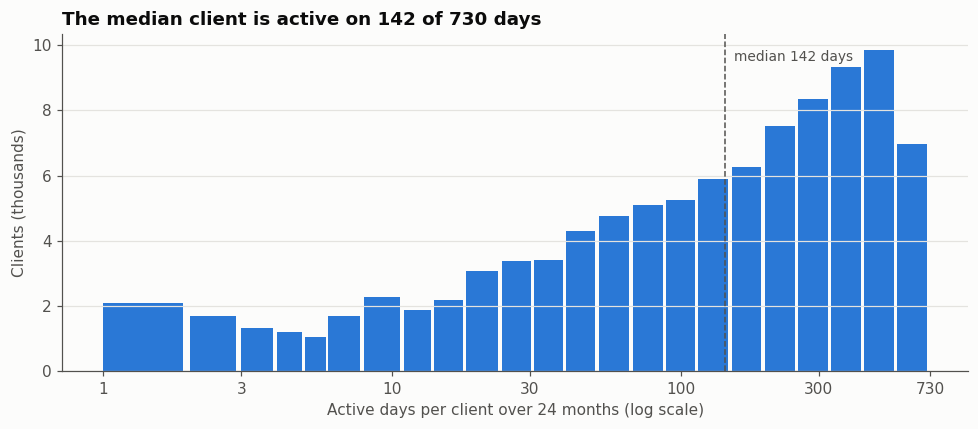

In [78]:
x = per_client["active_days"].to_numpy()
# Log-spaced bins on whole days, so small counts (1, 2, 3 days) do not leave empty bins
edges = np.unique(np.round(np.logspace(0, np.log10(x.max() + 1), 26)))
counts, edges = np.histogram(x, bins=edges)

fig, ax = plt.subplots()
ax.bar(edges[:-1], counts / 1e3, width=np.diff(edges) * 0.88, align="edge", color=BLUE)
ax.set_xscale("log")
ticks = [1, 3, 10, 30, 100, 300, 730]
ax.set_xticks(ticks, [str(t) for t in ticks])
ax.xaxis.set_minor_locator(mticker.NullLocator())
ax.set_xlabel("Active days per client over 24 months (log scale)")
ax.set_ylabel("Clients (thousands)")
median = per_client["active_days"].median()
ax.axvline(median, color=INK_2, lw=1, ls="--")
ax.annotate(f"median {median:.0f} days", (median, ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=INK_2, fontsize=9)
ax.set_title(f"The median client is active on {median:.0f} of 730 days")
plt.tight_layout()
plt.show()

In [79]:
joined = (per_client.group_by(pl.col("first_day").dt.truncate("1mo").alias("month"))
          .len().sort("month").to_pandas().set_index("month"))
print(f"clients whose first transaction is in Jan 2021: {joined['len'].iloc[0]:,} "
      f"({joined['len'].iloc[0] / per_client.height:.0%})")
print(f"clients who first appear later (new or returning clients): {per_client.height - joined['len'].iloc[0]:,}")
joined.T

clients whose first transaction is in Jan 2021: 69,205 (70%)
clients who first appear later (new or returning clients): 29,516


month,2021-01-01,2021-02-01,2021-03-01,2021-04-01,2021-05-01,2021-06-01,2021-07-01,2021-08-01,2021-09-01,2021-10-01,...,2022-03-01,2022-04-01,2022-05-01,2022-06-01,2022-07-01,2022-08-01,2022-09-01,2022-10-01,2022-11-01,2022-12-01
len,69205,3877,2457,1725,1417,1242,1189,1048,1013,1001,...,1100,1038,1052,1127,1164,1073,1068,1104,1130,927


**Result.** Activity is very uneven. The median client transacts on 142 of 730 days;
one in ten is active on 9 days or fewer. One client has over a million transactions,
probably a payment processor; it is kept, since the label depends on active days, not
on volume.

Seventy percent of clients already transact in January 2021. The early months also catch
existing clients whose first transaction simply came later; from mid-2021 about 1,000
to 1,200 clients appear for the first time each month. So the population **grows** over
time, and new clients have a short history when they are scored. Features must cope with
that, for example with a tenure feature.

### Activity over time

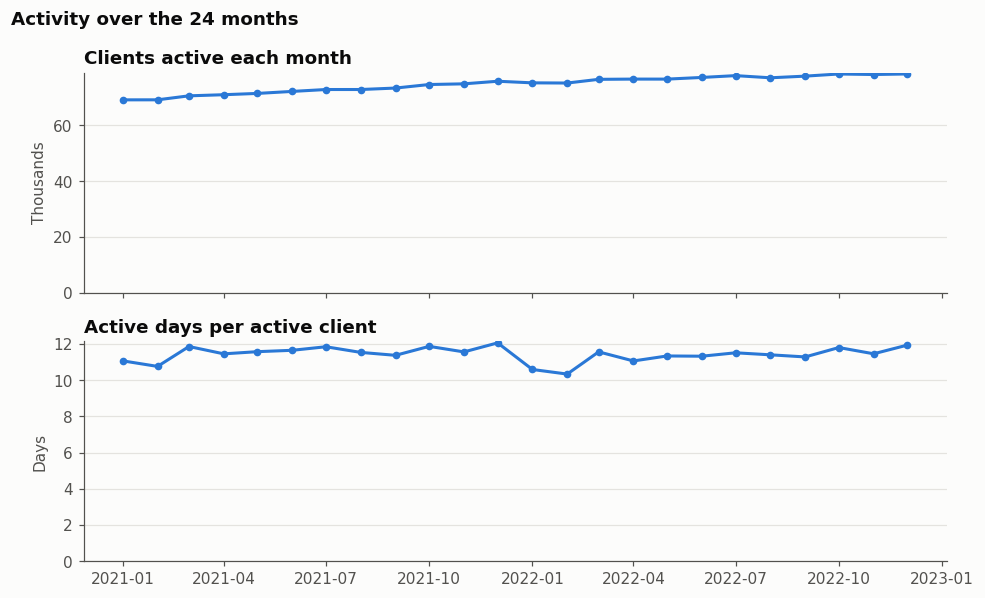

In [80]:
monthly = (
    active_days.group_by(pl.col("day").dt.truncate("1mo").alias("month"))
    .agg(pl.col("client_key").n_unique().alias("active_clients"), pl.len().alias("client_days"))
    .sort("month").to_pandas().set_index("month")
)
monthly["active_days_per_client"] = monthly["client_days"] / monthly["active_clients"]

fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
axes[0].plot(monthly.index, monthly["active_clients"] / 1e3, color=BLUE, lw=2, marker="o", ms=4)
axes[0].set_ylabel("Thousands")
axes[0].set_title("Clients active each month")
axes[0].set_ylim(0, None)
axes[1].plot(monthly.index, monthly["active_days_per_client"], color=BLUE, lw=2, marker="o", ms=4)
axes[1].set_ylabel("Days")
axes[1].set_title("Active days per active client")
axes[1].set_ylim(0, None)
fig.suptitle("Activity over the 24 months", x=0.01, ha="left", fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

**Result.** There are no missing months or sudden breaks. Active clients grow steadily
from about 69,000 to 78,000 a month, and an active client transacts on 11 to 12 days a
month. The small dips in January and February each year fit the long New Year holidays
and February's shorter month. The data feed looks stable enough to compare months.

### When does inactivity become dormancy?

An **inactivity spell** is the run of days between two active days, or between the last
active day and the end of the data. Banks call an account dormant once a spell reaches
some length N. The data does not tell us N, so we choose it from the data.

The question that decides N: *once a client has been inactive for d days, how likely are
they to come back soon?* If most clients come back after 20 quiet days, 20 days is a
pause, not dormancy. N should sit where coming back becomes the exception.

For each threshold d we take every spell that reached d days, keep only those with at
least 90 days of data after day d (so a return could be seen), and measure the share
that ended with a transaction within those 90 days.

In [81]:
END = LAST_DAY + timedelta(days=1)   # first day after the data

spells = (
    active_days
    .with_columns(pl.col("day").shift(-1).over("client_key").alias("next_day"))
    .with_columns(
        pl.col("next_day").is_null().alias("censored"),                     # last spell: still running at END
        pl.coalesce("next_day", pl.lit(END)).alias("spell_end"),
    )
    .with_columns(((pl.col("spell_end") - pl.col("day")).dt.total_days() - 1).alias("inactive_days"))
    .rename({"day": "start"})
    .select("client_key", "start", "next_day", "inactive_days", "censored")
    .filter(pl.col("inactive_days") > 0)
)
print(f"inactivity spells (at least one quiet day): {spells.height:,}")
print(f"  of which still running at the end of the data: {spells['censored'].sum():,}")
spells.select("inactive_days").to_pandas().describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).T

inactivity spells (at least one quiet day): 8,643,657
  of which still running at the end of the data: 70,271


,count,mean,std,min,50%,75%,90%,95%,99%,max
inactive_days,8643657.0,4.833553,15.504144,1.0,2.0,4.0,9.0,15.0,46.0,728.0


In [82]:
FOLLOW_UP = 90
rows = []
for d in range(7, 181, 1):
    reached = spells.filter(pl.col("inactive_days") >= d).with_columns(
        (pl.col("start") + pl.duration(days=d)).alias("day_d"))
    eligible = reached.filter(pl.col("day_d") + pl.duration(days=FOLLOW_UP) <= pl.lit(LAST_DAY))
    returned = eligible.filter(~pl.col("censored") &
                               (pl.col("next_day") <= pl.col("day_d") + pl.duration(days=FOLLOW_UP)))
    rows.append({"d": d, "spells_reaching_d": eligible.height,
                 "return_within_90d": returned.height / max(eligible.height, 1)})
reactivation = pd.DataFrame(rows).set_index("d")
reactivation.loc[[7, 14, 30, 45, 60, 90, 120, 180]]

,spells_reaching_d,return_within_90d
d,,
7,1098410,0.969135
14,438509,0.928736
30,142184,0.814803
45,76533,0.702220
60,50174,0.602424
90,29869,0.495865
120,20622,0.431384
180,11120,0.365288


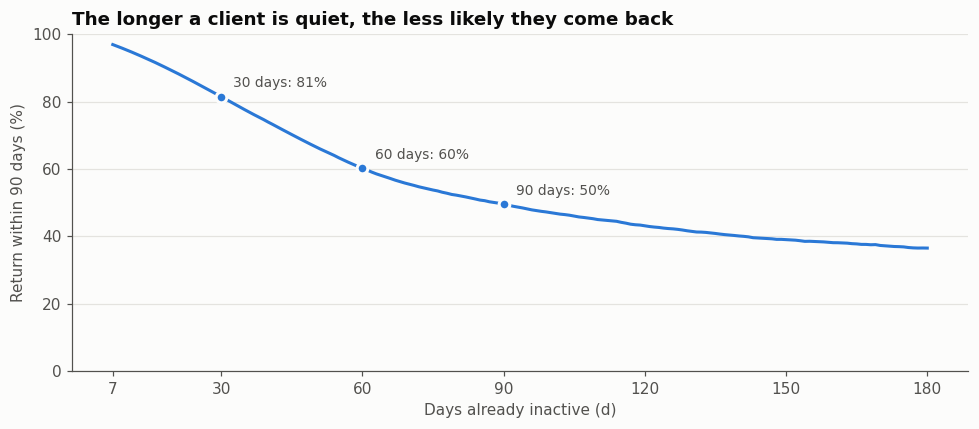

In [83]:
fig, ax = plt.subplots()
ax.plot(reactivation.index, reactivation["return_within_90d"] * 100, color=BLUE, lw=2)
for n in (30, 60, 90):
    y = reactivation.loc[n, "return_within_90d"] * 100
    ax.plot(n, y, "o", color=BLUE, ms=7, mec="#fcfcfb", mew=2)
    ax.annotate(f"{n} days: {y:.0f}%", (n, y), xytext=(8, 6), textcoords="offset points",
                color=INK_2, fontsize=9)
ax.set_xlabel("Days already inactive (d)")
ax.set_ylabel("Return within 90 days (%)")
ax.set_ylim(0, 100)
ax.set_xticks([7, 30, 60, 90, 120, 150, 180])
ax.set_title("The longer a client is quiet, the less likely they come back")
plt.tight_layout()
plt.show()

**Result.** Most quiet spells are short: the median is 2 days and 99% end within 46 days.
The return curve falls smoothly, **with no sharp elbow**: 81% of clients come back within
90 days after 30 quiet days, 60% after 60 days, 50% after 90 days and still 37% after 180
days. Corporate clients pause and come back far more than the word "dormant" suggests.

So the data cannot pick N on its own; it is partly a business choice. What the curve
does show is how much each N means: at 30 days, four in five "dormant" clients come back
soon, so the label would mostly mark ordinary pauses.

### Dormancy windows compared

A good N balances three things: coming back after N days should be rare (the label means
something), dormancy should be common enough to learn from, and the bank should still
have time to act. The table compares candidates using monthly **scoring dates**: on
each date, the **at-risk** clients are those that have transacted before and are not
already dormant; the **event** is crossing N quiet days within the next 90 days.

In [84]:
HORIZON = 90
SCORING_DATES = [date(y, m, 1) for y in (2021, 2022) for m in range(1, 13)
                 if date(2021, 4, 1) <= date(y, m, 1) <= date(2022, 10, 1)]
print(f"{len(SCORING_DATES)} scoring dates: {SCORING_DATES[0]} to {SCORING_DATES[-1]}")
print("(starting April 2021 leaves 90 days of history for features;"
      " ending October 2022 leaves 90 days to observe the outcome)")


def crossings(n: int) -> pl.DataFrame:
    # Day on which each spell reaches n quiet days, if it does inside the data
    return (spells.filter(pl.col("inactive_days") >= n)
            .with_columns((pl.col("start") + pl.duration(days=n)).alias("cross_day"))
            .filter(pl.col("cross_day") <= pl.lit(LAST_DAY))
            .select("client_key", "cross_day").sort("client_key", "cross_day"))


def scoring_panel(n: int, horizon: int = HORIZON) -> pl.DataFrame:
    cross = crossings(n)
    frames = []
    for t in SCORING_DATES:
        last_before = (active_days.filter(pl.col("day") < t)
                       .group_by("client_key").agg(pl.col("day").max().alias("last_active")))
        at_risk = (last_before
                   .with_columns(((pl.lit(t) - pl.col("last_active")).dt.total_days()).alias("days_since_last"))
                   .filter(pl.col("days_since_last") <= n)       # fewer than n quiet days: not yet dormant
                   .with_columns(pl.lit(t).alias("score_date")))
        nxt = (at_risk.sort("client_key")
               .join_asof(cross.rename({"cross_day": "next_cross"}), left_on="score_date",
                          right_on="next_cross", by="client_key", strategy="forward",
                          check_sortedness=False))
        frames.append(nxt.with_columns(
            (pl.col("next_cross").is_not_null() &
             (pl.col("next_cross") <= pl.col("score_date") + pl.duration(days=horizon))).alias("event")))
    return pl.concat(frames)


summary = []
panels = {}
for n in (30, 45, 60, 90, 180):
    panel = scoring_panel(n)
    panels[n] = panel
    ever = crossings(n)["client_key"].n_unique() / population.height
    summary.append({
        "N (quiet days)": n,
        "return within 90d after N": reactivation.loc[n, "return_within_90d"],
        "clients ever dormant": ever,
        "at-risk rows (all dates)": panel.height,
        "event rate per scoring date": panel["event"].mean(),
    })
pd.DataFrame(summary).set_index("N (quiet days)").style.format({
    "return within 90d after N": "{:.0%}", "clients ever dormant": "{:.0%}",
    "at-risk rows (all dates)": "{:,}", "event rate per scoring date": "{:.1%}"})

19 scoring dates: 2021-04-01 to 2022-10-01
(starting April 2021 leaves 90 days of history for features; ending October 2022 leaves 90 days to observe the outcome)


,return within 90d after N,clients ever dormant,at-risk rows (all dates),event rate per scoring date
N (quiet days),,,,
30,81%,49%,"1,418,511",18.8%
45,70%,39%,"1,469,511",12.5%
60,60%,32%,"1,499,829",9.2%
90,50%,25%,"1,539,167",6.5%
180,37%,13%,"1,595,993",2.6%


**Decision: N = 90 quiet days**, with N = 60 kept as a sensitivity check.

- **It matches practice.** The dissertation concept note says banks flag dormancy after
  90 to 180 days of no activity. N = 90 is the earliest of those flags, so the model
  warns before the bank's first formal flag.
- **The label means something.** After 90 quiet days, half of clients do not come back
  within the next 90 days. At 30 to 60 days most do, so the label would mark pauses.
- **There are still enough events.** About 6.5% of at-risk clients cross the threshold
  within 90 days, roughly 100,000 positive rows across all scoring dates. At N = 180 the
  rate falls to 2.6%, and with 24 months of data far fewer 180-day spells are observable.

*Honest limitation:* even at N = 90, half of the clients who cross the threshold
transact again later. The label therefore means **"crosses the bank's inactivity
threshold"**, the point that triggers dormancy handling, not "lost for good".

### At-risk population and event rate per scoring date (N = 90)

Check that the label is stable across time.

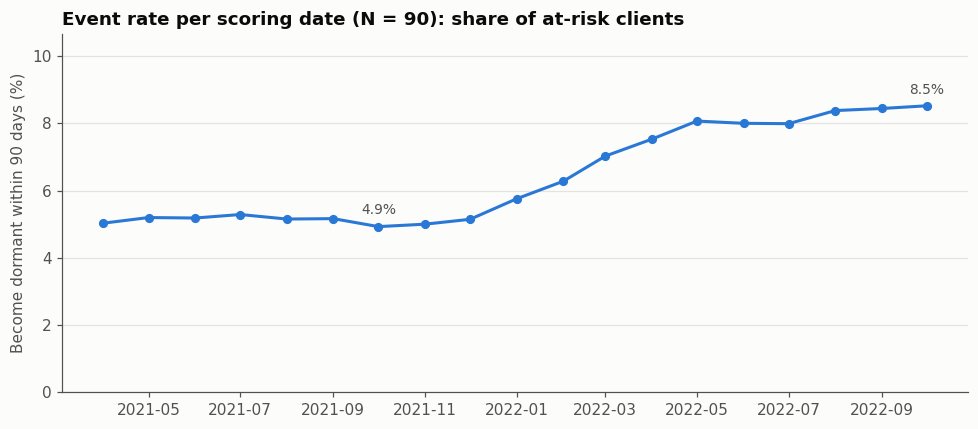

score_date,2021-04-01 00:00:00,2021-05-01 00:00:00,2021-06-01 00:00:00,2021-07-01 00:00:00,2021-08-01 00:00:00,2021-09-01 00:00:00,2021-10-01 00:00:00,2021-11-01 00:00:00,2021-12-01 00:00:00,2022-01-01 00:00:00,2022-02-01 00:00:00,2022-03-01 00:00:00,2022-04-01 00:00:00,2022-05-01 00:00:00,2022-06-01 00:00:00,2022-07-01 00:00:00,2022-08-01 00:00:00,2022-09-01 00:00:00,2022-10-01 00:00:00
at_risk,"75,539.000","76,211.000","76,824.000","77,417.000","77,878.000","78,475.000","78,964.000","79,678.000","80,392.000","81,159.000","81,774.000","82,585.000","83,298.000","83,883.000","84,254.000","84,699.000","84,978.000","85,347.000","85,812.000"
event_rate,0.050,0.052,0.052,0.053,0.052,0.052,0.049,0.050,0.051,0.058,0.063,0.070,0.075,0.081,0.080,0.080,0.084,0.084,0.085


In [85]:
N = 90   # chosen in section 5; change here to rerun sections 6-8 for another window
panel = panels[N]
by_date = (panel.group_by("score_date").agg(pl.len().alias("at_risk"), pl.col("event").mean().alias("event_rate"))
           .sort("score_date").to_pandas().set_index("score_date"))

fig, ax = plt.subplots()
ax.plot(by_date.index, by_date["event_rate"] * 100, color=BLUE, lw=2, marker="o", ms=5)
ax.set_ylim(0, by_date["event_rate"].max() * 100 * 1.25)
ax.set_ylabel("Become dormant within 90 days (%)")
ax.set_title(f"Event rate per scoring date (N = {N}): share of at-risk clients")
lo, hi = by_date["event_rate"].idxmin(), by_date["event_rate"].idxmax()
for when in (lo, hi):
    ax.annotate(f"{by_date.loc[when, 'event_rate']:.1%}", (when, by_date.loc[when, "event_rate"] * 100),
                xytext=(0, 8), textcoords="offset points", ha="center", color=INK_2, fontsize=9)
plt.tight_layout()
plt.show()
by_date.T.style.format("{:,.3f}")

**Result.** Two things change over time:

- **The at-risk population grows** from about 75,500 to 85,800 clients, matching the
  steady arrival of new clients.
- **The event rate drifts upwards.** It stays near 5% until late 2021, then climbs
  through 2022 to about 8.5%. The data does not say why.

Consequences for modelling: the out-of-time test period (the latest dates) has a
higher base rate than the training period. A model trained on 2021 alone would
under-predict risk in 2022, so calibration has to be checked on the test period, recent
dates should be in training, and this is exactly the kind of shift the drift monitoring
in the proposal is meant to catch.

### How much does recency alone tell us?

The simplest early-warning rule is "flag clients who have been quiet for a while". If
recency already separates the classes almost perfectly, a model adds little; if not,
there is room for the other signals. This also previews the **rule baseline** the models
must beat.

rows already quiet 30+ days: 7.8% of rows, 65.3% of events


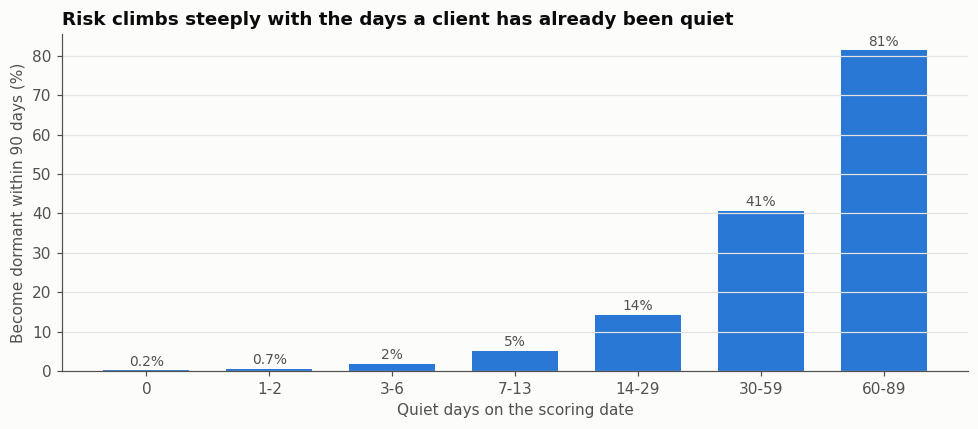

,rows,event_rate,share_of_rows,events
bucket,,,,
0,"534,817",0.2%,34.7%,"1,227"
1-2,"358,153",0.7%,23.3%,"2,353"
3-6,"241,599",1.9%,15.7%,"4,693"
7-13,"157,632",5.2%,10.2%,"8,203"
14-29,"126,310",14.3%,8.2%,"18,125"
30-59,"81,318",40.6%,5.3%,"33,052"
60-89,"39,338",81.4%,2.6%,"32,020"


In [86]:
edges_q = [0, 1, 3, 7, 14, 30, 60, N]
labels = ["0", "1-2", "3-6", "7-13", "14-29", "30-59", f"60-{N - 1}"]
quiet = panel.select((pl.col("days_since_last") - 1).alias("quiet_days"), "event").to_pandas()
quiet["bucket"] = pd.cut(quiet["quiet_days"], bins=edges_q, labels=labels, right=False)
recency = quiet.groupby("bucket", observed=False).agg(rows=("event", "size"), event_rate=("event", "mean"))
recency["share_of_rows"] = recency["rows"] / recency["rows"].sum()
recency["events"] = recency["rows"] * recency["event_rate"]
late = ["30-59", f"60-{N - 1}"]
print(f"rows already quiet 30+ days: {recency.loc[late, 'rows'].sum() / recency['rows'].sum():.1%} of rows, "
      f"{recency.loc[late, 'events'].sum() / recency['events'].sum():.1%} of events")

fig, ax = plt.subplots()
ax.bar(range(len(recency)), recency["event_rate"] * 100, color=BLUE, width=0.7)
ax.set_xticks(range(len(recency)), recency.index)
ax.set_xlabel("Quiet days on the scoring date")
ax.set_ylabel("Become dormant within 90 days (%)")
for i, v in enumerate(recency["event_rate"] * 100):
    ax.annotate(f"{v:.1f}%" if v < 1 else f"{v:.0f}%", (i, v), xytext=(0, 3), textcoords="offset points", ha="center", color=INK_2, fontsize=9)
ax.set_title("Risk climbs steeply with the days a client has already been quiet")
plt.tight_layout()
plt.show()
recency.style.format({"rows": "{:,}", "event_rate": "{:.1%}", "share_of_rows": "{:.1%}", "events": "{:,.0f}"})

**Result.** Recency is a strong signal, but it splits the problem into two very
different parts:

- **Clients already quiet for 30+ days** are 8% of at-risk rows but produce about two
  thirds of the events (see the printed share above). For them, the outcome is close to
  decided; a simple "days quiet" rule catches them.
- **Clients active in the last week** are about three quarters of the rows, with event
  rates of 0.2 to 2%. Here recency says little, and this is where an early warning is
  worth the most, because the bank can still act.

So: the **rule baseline** will be "days quiet", and model results will be reported
**separately for clients quiet fewer than 30 days**. A model that only rediscovers
recency would look good overall and add nothing where it matters.

### Is there a warning signal before dormancy?

Compare two groups over the 26 weeks leading up to an anchor day:

- **Became dormant:** each client's first spell of N+ quiet days; the anchor is the
  last active day before it.
- **Stayed active:** clients who never had an N-day spell; the anchor is a random active
  day, so both groups are anchored on a day with activity.

Activity is measured as active days per week and indexed to each group's own level 14 to
26 weeks before the anchor (= 100). A falling line means activity was already fading.

In [87]:
WEEKS = 26
early = FIRST_DAY + timedelta(days=7 * WEEKS)          # need 26 weeks of history
late = LAST_DAY - timedelta(days=N)                    # dormant anchors need N days of follow-up

dormant_anchor = (crossings(N).group_by("client_key").agg(pl.col("cross_day").min())
                  .with_columns((pl.col("cross_day") - pl.duration(days=N)).alias("anchor"))
                  .filter(pl.col("anchor").is_between(early, late))
                  .select("client_key", "anchor").with_columns(pl.lit("Became dormant").alias("group")))

ever_dormant = crossings(N)["client_key"].unique()
active_anchor = (active_days.filter(~pl.col("client_key").is_in(ever_dormant.implode())
                                    & pl.col("day").is_between(early, late))
                 .group_by("client_key").agg(pl.col("day").shuffle(seed=42).first().alias("anchor"))
                 .with_columns(pl.lit("Stayed active").alias("group")))
anchors = pl.concat([dormant_anchor, active_anchor.select(dormant_anchor.columns)])
print(anchors.group_by("group").len())

weekly = (anchors.join(active_days, on="client_key")
          .with_columns(((pl.col("anchor") - pl.col("day")).dt.total_days() // 7 + 1).alias("weeks_before"))
          .filter(pl.col("weeks_before").is_between(1, WEEKS) & (pl.col("day") <= pl.col("anchor")))
          .group_by("group", "weeks_before").agg(pl.len().alias("days"))
          .join(anchors.group_by("group").len().rename({"len": "clients"}), on="group")
          .with_columns((pl.col("days") / pl.col("clients")).alias("active_days_per_week"))
          .sort("group", "weeks_before").to_pandas())
pivot = weekly.pivot(index="weeks_before", columns="group", values="active_days_per_week").sort_index()
index = pivot / pivot.loc[14:26].mean() * 100
# Week 1 always contains the anchor, an active day by construction, so it is left out of the chart
plot_index = index.loc[2:]
pivot.round(2).T

shape: (2, 2)
┌────────────────┬───────┐
│ group          ┆ len   │
│ ---            ┆ ---   │
│ str            ┆ u32   │
╞════════════════╪═══════╡
│ Became dormant ┆ 16966 │
│ Stayed active  ┆ 71125 │
└────────────────┴───────┘


weeks_before,1,2,3,4,5,6,7,8,9,10,...,17,18,19,20,21,22,23,24,25,26
group,,,,,,,,,,,,,,,,,,,,,
Became dormant,1.34,0.45,0.50,0.54,0.57,0.56,0.53,0.53,0.53,0.55,...,0.59,0.59,0.61,0.60,0.62,0.62,0.63,0.62,0.64,0.63
Stayed active,3.49,2.88,2.86,2.85,2.82,2.79,2.77,2.76,2.77,2.76,...,2.71,2.71,2.70,2.69,2.68,2.68,2.67,2.66,2.66,2.65


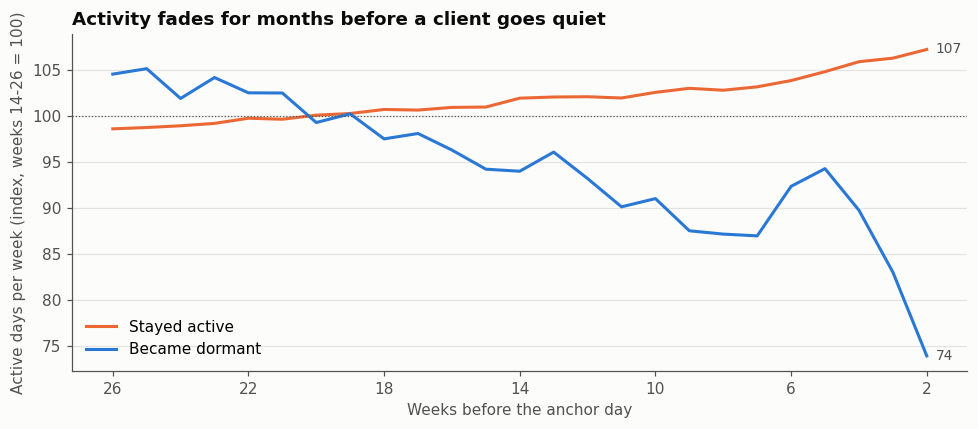

In [88]:
fig, ax = plt.subplots()
for group, color in [("Stayed active", ORANGE), ("Became dormant", BLUE)]:
    ax.plot(-plot_index.index, plot_index[group], color=color, lw=2, label=group)
    ax.annotate(f"{plot_index.loc[2, group]:.0f}", (-2, plot_index.loc[2, group]),
                xytext=(6, 0), textcoords="offset points", va="center", color=INK_2, fontsize=9)
ax.axhline(100, color=INK_2, lw=0.8, ls=":")
ax.set_xlabel("Weeks before the anchor day")
ax.set_xticks([-26, -22, -18, -14, -10, -6, -2])
ax.set_ylabel("Active days per week (index, weeks 14-26 = 100)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{-int(v)}"))
ax.legend(loc="lower left")
ax.set_title("Activity fades for months before a client goes quiet")
plt.tight_layout()
plt.show()

**Result.** There is a clear warning signal. Clients who go dormant are already much
less active (about 0.6 active days a week against 2.7), and **their activity fades for
about four months before the last transaction**: roughly 10% down by week 10 and 26% down
in the final two weeks. Clients who stay active hold steady or rise slightly.

*Caveat:* the rising line for "stayed active" is partly built in, because those anchors
are active days of clients who stayed active. The useful part is the shape of the
dormant line. It argues for **trend features** (recent weeks against earlier weeks), not
only levels.

### What kinds of transactions are there?

In [89]:
types = run(trx.group_by("event_type").agg(pl.len().alias("rows"), pl.col("client_key").n_unique().alias("clients")))
types = types.with_columns((pl.col("rows") / pl.col("rows").sum()).alias("share_of_rows"),
                           (pl.col("clients") / population.height).alias("share_of_clients")).sort("rows", descending=True)
top = types.head(10).to_pandas().set_index("event_type")
print(f"{types.height} transaction types; the top 10 cover {top['share_of_rows'].sum():.0%} of rows")
top.style.format({"rows": "{:,}", "clients": "{:,}", "share_of_rows": "{:.1%}", "share_of_clients": "{:.0%}"})

55 transaction types; the top 10 cover 91% of rows


,rows,clients,share_of_rows,share_of_clients
event_type,,,,
1,"16,763,280","91,395",43.2%,93%
46,"5,594,429","56,139",14.4%,57%
40,"4,524,387","44,803",11.7%,45%
49,"2,991,195","40,759",7.7%,41%
11,"2,091,135","34,629",5.4%,35%
56,"819,612","38,157",2.1%,39%
41,"797,243","35,046",2.1%,36%
50,"686,953","26,763",1.8%,27%
18,"602,747","28,976",1.6%,29%


**Result.** Transaction types are highly concentrated. Type 1 alone is 43% of rows and is
used by 93% of clients; the top 10 types cover 91% of rows. Type 48, the one with the
most missing attributes, is used by only 8% of clients.

**Decision.** Features will count activity for the top types separately and group the
rest as "other". A change in a client's transaction mix may itself be a signal.

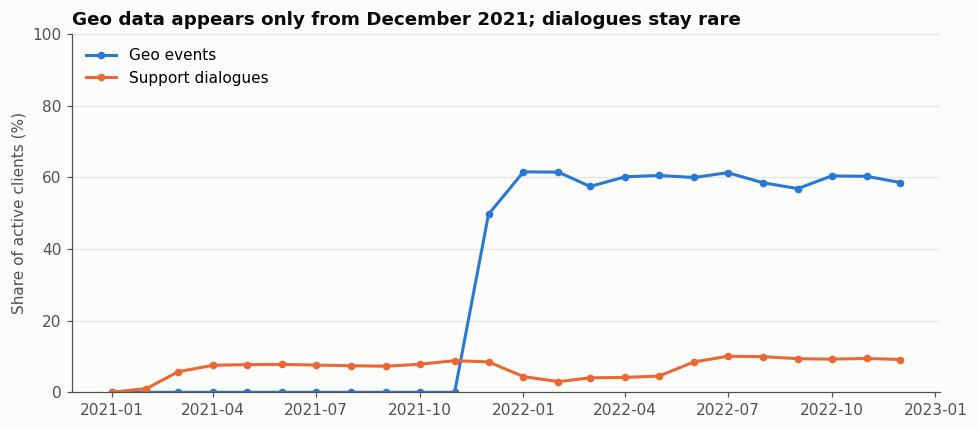

In [90]:
month_active = active_days.select("client_key", pl.col("day").dt.truncate("1mo").alias("month")).unique()
geo_months = run(pl.scan_parquet(INTERIM / "geo_clean.parquet")
                 .select("client_key", pl.col("event_time_local").dt.date().dt.truncate("1mo").alias("month")).unique())
dialog_months = (pl.read_parquet(INTERIM / "dialog_clean.parquet", columns=["client_key", "event_time_local"])
                 .select("client_key", pl.col("event_time_local").dt.date().dt.truncate("1mo").alias("month")).unique())
coverage = (month_active
            .join(geo_months.with_columns(pl.lit(True).alias("geo")), on=["client_key", "month"], how="left")
            .join(dialog_months.with_columns(pl.lit(True).alias("dialog")), on=["client_key", "month"], how="left")
            .group_by("month").agg(pl.col("geo").is_not_null().mean(), pl.col("dialog").is_not_null().mean())
            .sort("month").to_pandas().set_index("month"))

fig, ax = plt.subplots()
ax.plot(coverage.index, coverage["geo"] * 100, color=BLUE, lw=2, marker="o", ms=4, label="Geo events")
ax.plot(coverage.index, coverage["dialog"] * 100, color=ORANGE, lw=2, marker="o", ms=4, label="Support dialogues")
ax.set_ylim(0, 100)
ax.set_ylabel("Share of active clients (%)")
ax.legend(loc="upper left")
ax.set_title("Geo data appears only from December 2021; dialogues stay rare")
plt.tight_layout()
plt.show()

**Result.** Geo data is absent until December 2021 and then covers about 60% of active
clients each month from January 2022. Support dialogues reach 5 to 10% of active clients
a month.

**Decision.** The core model uses **transaction features only**, so all 19 scoring dates
can be used. Geo and dialogue features are tested as an **add-on** on 2022 scoring dates
(from March 2022, once 90 days of geo history exist), to see whether they add anything
beyond transactions. Dialogues start as simple counts and recency; the 768-dimension
embeddings are a stretch goal.

### Summary and decisions

| Question | Decision
|---|---|
| Dormancy window N | **90 quiet days** (60 as sensitivity) |
| Label | Crosses N quiet days within 30, 60 and 90 days of the scoring date |
| Scoring dates | 19 monthly dates, 1 Apr 2021 to 1 Oct 2022 |
| At-risk population | Transacted before the date and fewer than N days quiet |
| Censoring | None needed for the 90-day horizon on these dates |
| Baseline | Days quiet on the scoring date |
| Evaluation | Out-of-time split; results also for clients quiet < 30 days |
| Drift | Event rate rises from about 5% to 8.5% |
| Core features | Activity level, trend (recent vs earlier weeks), recency, tenure, transaction-type mix, amounts in currency 11 |
| Geo and dialogue | Add-on test on 2022 dates only |